# Cvičenie V — semivariogram a kriging
----------------

### Setup and reproducibility

Run from top to bottom using the dependencies in `requirements.txt`. The Meuse CSV and an attributed Esri WorldTopoMap raster are cached in `data/`; their provenance and checksums are in `data/sources.json`. Paths support either the workspace root or this notebook's directory. Tables and prediction grids are exported to `results/`.

All variogram and kriging distances use the original **EPSG:28992 coordinates in meters**. EPSG:3857 is used only for the requested basemap display: Web Mercator distances would be distorted at this latitude. Concentrations are topsoil ppm (mg/kg). The natural logarithm is used for all lead and cadmium variograms unless a plot is explicitly labeled as the original scale.

In [2]:
from pathlib import Path
from urllib.request import urlopen
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as cx
import rasterio
from rasterio.transform import from_bounds
from scipy.spatial import KDTree, Delaunay, ConvexHull
from scipy.spatial.distance import pdist
from scipy.optimize import brentq
from sklearn.model_selection import KFold
from IPython.display import display
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='IProgress not found.*')
    import skgstat as skg

exercise_dir = Path('.') if Path('05_exercises.ipynb').is_file() else Path('05_exercises')
data_dir, results_dir = exercise_dir / 'data', exercise_dir / 'results'
data_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)
print('Versions:', 'numpy', np.__version__, 'pandas', pd.__version__,
      'geopandas', gpd.__version__, 'scikit-gstat', skg.__version__)


def cached_file(filename, url):
    file = data_dir / filename
    if not file.is_file():
        with urlopen(url, timeout=90) as response:
            content = response.read()
        if not content:
            raise ValueError(f'Empty download: {url}')
        file.write_bytes(content)
    return file


def fit_variogram(values, model='spherical', n_lags=12, maxlag='median', use_nugget=True, **kwargs):
    return skg.Variogram(coordinates, np.asarray(values), estimator='matheron',
                         model=model, n_lags=n_lags, maxlag=maxlag, bin_func='even',
                         use_nugget=use_nugget, normalize=False, fit_method='trf', **kwargs)


def variogram_metrics(v):
    desc = v.describe()
    partial_sill = float(desc['sill'])
    nugget = float(desc.get('nugget', 0.0))
    last_lag = float(v.bins[-1])
    effective_range = float(desc['effective_range'])
    fraction = float((v.fitted_model(last_lag) - nugget) / partial_sill)
    # Calculate the 95% distance from the actual installed model function,
    # rather than assuming every family's range parameter means exactly 95%.
    h95 = brentq(lambda h: float(v.fitted_model(h) - nugget - 0.95 * partial_sill),
                  1e-12, 20 * effective_range)
    row = {'Model': desc['model'], 'n_lags': v.n_lags, 'Maxlag_m': last_lag,
           'Lag_width_m': float(v.bins[1] - v.bins[0]),
           'Min_pairs': int(np.min(v.bin_count)), 'Max_pairs': int(np.max(v.bin_count)),
           'Empty_bins': int(np.sum(v.bin_count == 0)),
           'Effective_range_m': effective_range, 'Partial_sill': partial_sill,
           'Nugget': nugget, 'Total_sill': partial_sill + nugget,
           'Variogram_RMSE': float(v.rmse), 'h95_m': h95,
           'Structured_sill_fraction_at_maxlag': fraction,
           'Practical_sill_95pct_in_window': fraction >= 0.95,
           'Exact_plateau_in_window': desc['model'] == 'spherical' and last_lag >= effective_range,
           'Smoothness': float(desc.get('smoothness', np.nan))}
    if not np.isfinite([effective_range, partial_sill, nugget, row['Variogram_RMSE']]).all():
        raise ValueError('Variogram parameters must be finite.')
    return row


def plot_variogram(v, ax, title, annotation=True):
    row = variogram_metrics(v)
    h = np.linspace(1e-9, row['Maxlag_m'], 400)
    ax.plot(v.bins, v.experimental, 'o', color='tab:blue', markersize=4, label='Empirical bins')
    ax.plot(h, v.fitted_model(h), color='black', label=row['Model'])
    ax.axhline(row['Total_sill'], color='tab:red', linestyle='--', linewidth=1, label='Total sill')
    ax.axhline(row['Nugget'], color='gray', linestyle=':', linewidth=1, label='Nugget')
    if row['Effective_range_m'] <= row['Maxlag_m']:
        ax.axvline(row['Effective_range_m'], color='tab:orange', linestyle=':', linewidth=1, label='Range parameter')
    ax.set(xlabel='Lag distance (m)', ylabel='Semivariance (log concentration)²', title=title)
    ax.grid(alpha=0.25)
    if annotation:
        text = (f"lags={row['n_lags']}; width={row['Lag_width_m']:.1f} m\n"
                f"maxlag={row['Maxlag_m']:.1f} m\n"
                f"range={row['Effective_range_m']:.1f} m; h95={row['h95_m']:.1f} m\n"
                f"partial sill={row['Partial_sill']:.4f}\n"
                f"nugget={row['Nugget']:.4f}; total sill={row['Total_sill']:.4f}\n"
                f"bin-fit RMSE={row['Variogram_RMSE']:.4f}\n"
                f"95% sill in window: {row['Practical_sill_95pct_in_window']}")
        if np.isfinite(row['Smoothness']):
            text += f"\nMatérn smoothness={row['Smoothness']:.3f}"
        ax.text(0.97, 0.04, text, transform=ax.transAxes, ha='right', va='bottom', fontsize=8,
                bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'lightgray'})
    return row


def lag_settings(xy, label):
    distances = pdist(xy)
    ann = float(KDTree(xy).query(xy, k=2)[0][:, 1].mean())
    choices = {'median': float(np.median(distances)), 'mean': float(np.mean(distances)),
               '0.5': float(np.max(distances) * 0.5)}
    cutoff = choices[label]
    return cutoff, ann, max(3, int(np.rint(cutoff / ann)))


def fit_cadmium(xy, values, label, model):
    cutoff, ann, n_lags = lag_settings(xy, label)
    variance = float(np.var(values, ddof=1))
    # Allow range to extend beyond the fitted window, so reaching a sill is
    # assessed from the curve rather than forced by a range <= maxlag bound.
    v = skg.Variogram(xy, values, estimator='matheron', model=model, bin_func='even',
                      n_lags=n_lags, maxlag=cutoff, use_nugget=True, normalize=False,
                      fit_method='trf',
                      fit_bounds=([0, 0, 0], [3 * cutoff, 3 * variance, 3 * variance]))
    return v, {'Maxlag_rule': label, 'ANN_m': ann, 'Derived_n_lags': n_lags}


def krige_points(v, targets):
    ok = skg.OrdinaryKriging(v, min_points=5, max_points=20, mode='exact', n_jobs=1)
    prediction = np.asarray(ok.transform(targets[:, 0], targets[:, 1]), dtype=float)
    variance = np.asarray(ok.sigma, dtype=float).copy()  # This field is variance, not SD.
    finite = np.isfinite(variance)
    if np.any(variance[finite] < -1e-8):
        raise ValueError('A materially negative kriging variance needs investigation.')
    variance[finite] = np.maximum(variance[finite], 0.0)
    return prediction, variance, ok


def kriging_surface(v, name, size=75):
    xy = v.coordinates
    x_edges = np.linspace(xy[:, 0].min(), xy[:, 0].max(), size + 1)
    y_edges = np.linspace(xy[:, 1].min(), xy[:, 1].max(), size + 1)
    xx, yy = np.meshgrid((x_edges[:-1] + x_edges[1:]) / 2,
                          (y_edges[:-1] + y_edges[1:]) / 2)
    targets = np.column_stack([xx.ravel(), yy.ravel()])
    inside = Delaunay(xy).find_simplex(targets) >= 0
    prediction = np.full(len(targets), np.nan)
    variance = np.full(len(targets), np.nan)
    prediction[inside], variance[inside], ok = krige_points(v, targets[inside])
    sd_log = np.sqrt(variance)
    median_ppm = np.exp(prediction)
    # Optional Gaussian/lognormal approximations are exported with explicit labels.
    mean_ppm_approx = np.exp(prediction + variance / 2)
    sd_ppm_approx = mean_ppm_approx * np.sqrt(np.expm1(variance))
    grid = pd.DataFrame({'x': targets[:, 0], 'y': targets[:, 1], 'Inside_hull': inside,
                         'Pred_log': prediction, 'Variance_log2': variance, 'Sigma_log': sd_log,
                         'Median_ppm': median_ppm, 'Mean_ppm_lognormal_approx': mean_ppm_approx,
                         'SD_ppm_lognormal_approx': sd_ppm_approx,
                         'Lower95_ppm_approx': np.exp(prediction - 1.96 * sd_log),
                         'Upper95_ppm_approx': np.exp(prediction + 1.96 * sd_log)})
    grid.to_csv(results_dir / f'{name}_kriging_grid.csv', index=False)
    valid = inside & np.isfinite(prediction) & np.isfinite(variance)
    print(f'{name}: {size}×{size}={len(grid)} grid cells; inside hull={inside.sum()}; '
          f'predicted={valid.sum()}; unsupported inside={int(inside.sum() - valid.sum())}.')
    print(f'Back-transformed median: {np.nanmin(median_ppm):.3f} to {np.nanmax(median_ppm):.3f} ppm; '
          f'log-scale SD: {np.nanmin(sd_log):.3f} to {np.nanmax(sd_log):.3f}.')
    hull_order = ConvexHull(xy).vertices
    hull_coords = xy[np.r_[hull_order, hull_order[0]]]
    fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharex=True, sharey=True)
    for ax, values, title, color, units in zip(
        axes, [median_ppm, sd_log],
        [f'{name.capitalize()}: exp(kriged log value)', f'{name.capitalize()}: kriging standard deviation'],
        ['viridis', 'magma'], ['Predicted median concentration (ppm)', 'σ on natural-log scale'],
    ):
        image = ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(values.reshape(size, size)),
                              cmap=color, shading='flat')
        ax.scatter(xy[:, 0], xy[:, 1], s=5, c='black', alpha=0.6, label='Samples')
        ax.plot(hull_coords[:, 0], hull_coords[:, 1], color='gray', linewidth=0.8)
        ax.set(title=title, xlabel='RD New easting (m)', ylabel='RD New northing (m)', aspect='equal')
        ax.ticklabel_format(style='plain', useOffset=False)
        fig.colorbar(image, ax=ax, label=units, shrink=0.7)
    fig.tight_layout()
    fig.savefig(results_dir / f'{name}_kriging_maps.png', dpi=160, bbox_inches='tight')
    plt.show()
    # Export georeferenced bands; arrays must run north-to-south in the raster.
    with rasterio.open(results_dir / f'{name}_kriging.tif', 'w', driver='GTiff',
                        height=size, width=size, count=3, dtype='float32', crs='EPSG:28992',
                        transform=from_bounds(x_edges[0], y_edges[0], x_edges[-1], y_edges[-1], size, size),
                        nodata=np.nan) as dst:
        for band, values, description in [(1, median_ppm, 'Predicted median concentration (ppm)'),
                                          (2, sd_log, 'Kriging standard deviation (natural-log scale)'),
                                          (3, variance, 'Kriging variance (natural-log scale squared)')]:
            dst.write(np.flipud(values.reshape(size, size)).astype('float32'), band)
            dst.set_band_description(band, description)
    return {'grid': grid, 'shape': xx.shape, 'inside': inside, 'valid': valid,
            'prediction': prediction, 'variance': variance, 'ok': ok}

Versions: numpy 2.5.3 pandas 3.1.0 geopandas 1.2.0 scikit-gstat 1.0.27


Observations: 155; modelling CRS: EPSG:28992; display CRS: EPSG:3857


,Min_ppm,Max_ppm,Mean_ppm,Raw_skewness,Log_skewness
lead,37.0,654.0,153.361290,1.652336,0.255421
zinc,113.0,1839.0,469.716129,1.486462,0.329075
copper,14.0,128.0,40.316129,1.414055,0.667568
cadmium,0.2,18.1,3.245806,1.796225,-0.337555


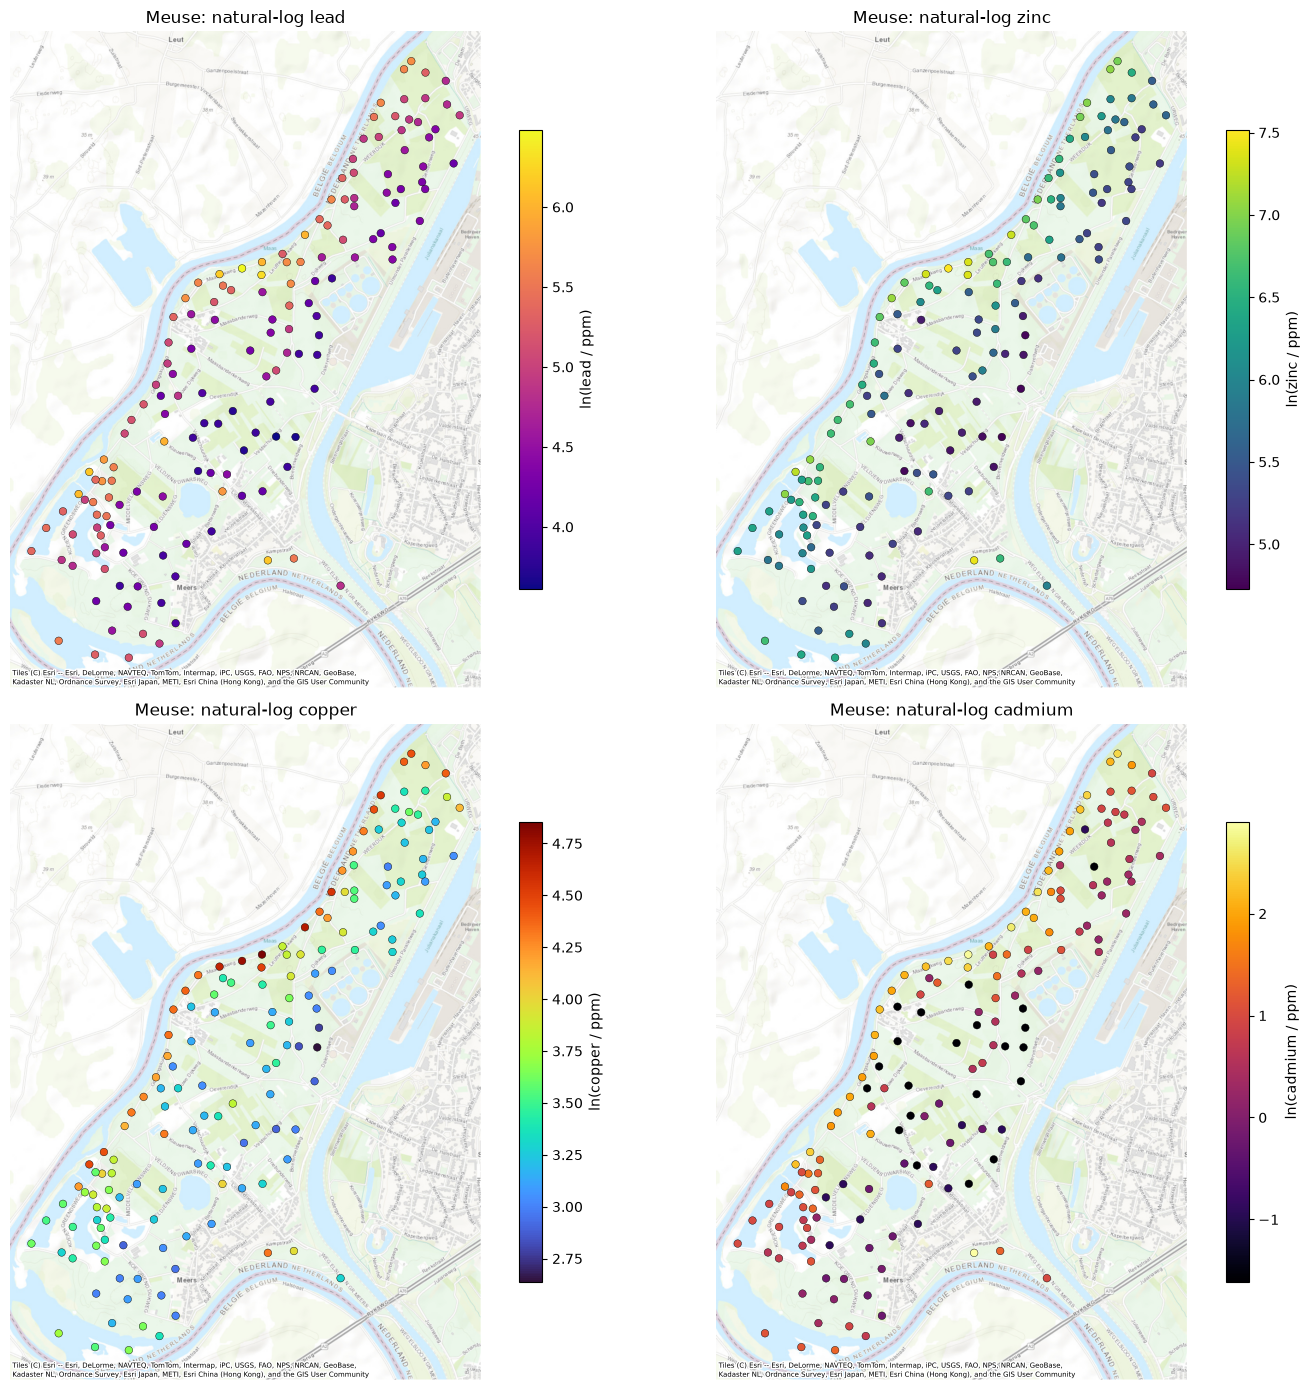

In [3]:
# TODO:
# 1. Načítanie priestorových dát (Meuse dataset):
#    - Načítajte súradnice (x, y) a koncentráciu  4 ťažkých kovov (lead, zinc, copper, cadmium).
#
# 2. Logaritmická transformácia koncentrácií:
#    - Pre každý kov vytvorte nový stĺpec 'log_*' pomocou prirodzeného logaritmu np.log():
#      (log_lead, log_zinc, log_copper, log_cadmium).
#
# 3. Vytvorenie GeoDataFrame a reprojekcia CRS:
#    - Vytvorte GeoDataFrame (gpd.GeoDataFrame) s geometriou bodov z 'x' a 'y' (gpd.points_from_xy).
#    - Nastavte pôvodný súradnicový systém holandskej siete: crs='EPSG:28992'.
#    - Pretransformujte dáta do Web Mercator pomocou .to_crs(epsg=3857).
#
# 4. Vizualizácia do mriežky 2x2 s podkladovou mapou:
#    - Vytvorte obrázok s mriežkou 2x2 grafov.
#    - Pre každý kov nastavte špecifickú farebnú škálu (cmap):
#      * log_lead: 'plasma'
#      * log_zinc: 'viridis'
#      * log_copper: 'turbo'
#      * log_cadmium: 'inferno'
#    - Do každého podgrafu vložte topografickú mapu cez cx.add_basemap(ax, source=cx.providers.Esri.WorldTopoMap, alpha=0.9).

meuse_url = 'https://raw.githubusercontent.com/mmaelicke/scikit-gstat/master/skgstat/data/samples/meuse.txt'
meuse = pd.read_csv(cached_file('meuse.csv', meuse_url))
metals = ['lead', 'zinc', 'copper', 'cadmium']
required = ['x', 'y', *metals]
if len(meuse) != 155 or not np.isfinite(meuse[required].to_numpy()).all():
    raise ValueError('Expected 155 complete Meuse observations for coordinates and metals.')
if meuse[['x', 'y']].duplicated().any() or (meuse[metals] <= 0).any().any():
    raise ValueError('Resolve duplicate locations or nonpositive concentrations before fitting.')
for metal in metals:
    meuse[f'log_{metal}'] = np.log(meuse[metal])
gdf = gpd.GeoDataFrame(meuse, geometry=gpd.points_from_xy(meuse.x, meuse.y), crs='EPSG:28992')
gdf_web = gdf.to_crs(epsg=3857)
coordinates = meuse[['x', 'y']].to_numpy(dtype=float)
log_lead = meuse.log_lead.to_numpy()
summary = pd.DataFrame({'Min_ppm': meuse[metals].min(), 'Max_ppm': meuse[metals].max(),
                         'Mean_ppm': meuse[metals].mean(), 'Raw_skewness': meuse[metals].skew(),
                         'Log_skewness': [meuse[f'log_{m}'].skew() for m in metals]})
print(f'Observations: {len(gdf)}; modelling CRS: {gdf.crs}; display CRS: {gdf_web.crs}')
display(summary)

basemap_path = data_dir / 'esri_worldtopo_meuse.tif'
if not basemap_path.is_file():
    xmin, ymin, xmax, ymax = gdf_web.total_bounds
    cx.bounds2raster(xmin - 150, ymin - 150, xmax + 150, ymax + 150, str(basemap_path),
                     zoom=15, source=cx.providers.Esri.WorldTopoMap, n_connections=1)
fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, metal, cmap in zip(axes.ravel(), metals, ['plasma', 'viridis', 'turbo', 'inferno']):
    gdf_web.plot(ax=ax, column=f'log_{metal}', cmap=cmap, markersize=30, edgecolor='black',
                   linewidth=0.3, legend=True, legend_kwds={'label': f'ln({metal} / ppm)', 'shrink': 0.7})
    cx.add_basemap(ax, source=str(basemap_path), alpha=0.9,
                   attribution=cx.providers.Esri.WorldTopoMap.attribution, attribution_size=5)
    ax.set_title(f'Meuse: natural-log {metal}')
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(results_dir / 'meuse_four_metals_basemap.png', dpi=150, bbox_inches='tight')
plt.show()


### Exercise 1 — interpretation

The four metals are measured at the same 155 sites. Natural logs compress large concentrations and can reduce right skewness; the table reports skewness before and after transformation. Logarithms do not remove spatial trend or establish stationarity. The source already contains strictly positive cadmium values, including 0.2 ppm; no new offset or imputation is introduced here. Unused auxiliary columns can contain missing values without removing complete metal observations.

The four maps use the required color palettes and the same cached Esri topographic source, with attribution retained. Their color scales are specific to each metal. Visual color intensity therefore cannot be compared across panels as though it were a common ppm scale.

## Kriging

Kriging je geostatistická interpolačná metóda, ktorá umožňuje odhadovať hodnoty na miestach, kde nemáme merania. Zohľadňuje pri tom vzťah medzi nameranými hodnotami v závislosti od ich vzdialenosti a smeru. Kriging predpokladá, že vzdialenosť alebo smer medzi vzorkovacími bodmi odráža priestorovú koreláciu, ktorú možno využiť na vysvetlenie priestorovej variability hodnôt.

Dva kroky:
- Identifikovať pravidlá priestorovej závislosti medzi nameranými hodnotami: variogramy.
- Vytvoriť predpovede na základe zistených priestorových vzťahov.

----------------

### 1. Semivariogram

Na obrázku nižšie je znázornené spárovanie jedného bodu so všetkými ostatnými nameranými lokalitami. Tento proces sa opakuje pre každý jeden nameraný bod. Podobné farby medzi dvojicami znamenajú podobné vzdialenosti.

<div align="center">
  <img src="img/paired_locations.png" alt="Calculating the difference squared between the paired locations" width="550"/>
</div>

Každá dvojica lokalít má často jedinečnú vzdialenosť a v dátach býva zvyčajne obrovské množstvo dvojíc bodov. Vykresliť všetky tieto dvojice sa rýchlo stáva neprehľadným. Namiesto vykresľovania každej jednotlivej dvojice sa body zoskupujú do lagových tried (binov).

Pre každú dvojicu bodov (ktoré sú od seba v rovnakej vzdialenosti) vypočítame druhú mocninu rozdielu ich hodnôt a tieto rozdiely sčítame. Pre výpočet variogramu vydelíme tento súčet celkovým počtom párov, a pre výpočet semivariogramu ho vydelíme $2N(h)$.

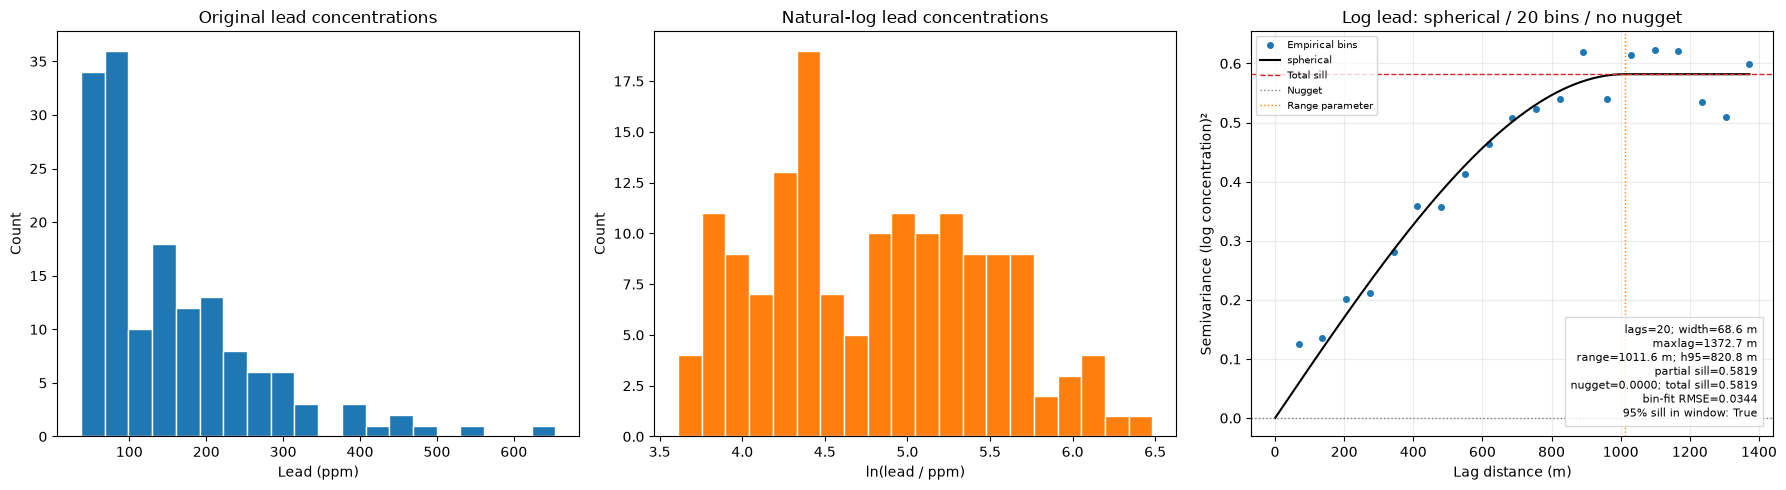

Model                                   spherical
n_lags                                         20
Maxlag_m                              1372.666019
Lag_width_m                             68.633301
Min_pairs                                      18
Max_pairs                                     387
Empty_bins                                      0
Effective_range_m                     1011.589399
Partial_sill                             0.581906
Nugget                                        0.0
Total_sill                               0.581906
Variogram_RMSE                           0.034407
h95_m                                  820.805006
Structured_sill_fraction_at_maxlag            1.0
Practical_sill_95pct_in_window               True
Exact_plateau_in_window                      True
Smoothness                                    NaN


In [4]:
# TODO:
# 1. Porovnanie pôvodných a log hodnôt olova:
#   - Použite histogram s bins=20
#   - Logaritmická transformácia môže znížiť asymetriu rozdelenia a vplyv extrémnych hodnôt, 
#       čo môže uľahčiť modelovanie semivariogramu.

# 2. Výpočet semivariogramu (skg.Variogram) a vykreslenie empirických bodov a teoretického modelu:
#    - Z logaritmovaných hodnôt koncentrácie olova súradníc (x, y) vypočítajte sférický semivariogram pomocou Matheronovho odhadu 
#       - 20 lagov(binov)
#       - maxlag='median'
#       - bin_func='even'
#       - use_nugget=False      
#    - Empirické body: Variogram.experimental
#    - teoretická krivka: Variogram.fitted_model()

lead_initial = fit_variogram(log_lead, model='spherical', n_lags=20, maxlag='median', use_nugget=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(meuse.lead, bins=20, color='tab:blue', edgecolor='white')
axes[0].set(xlabel='Lead (ppm)', ylabel='Count', title='Original lead concentrations')
axes[1].hist(log_lead, bins=20, color='tab:orange', edgecolor='white')
axes[1].set(xlabel='ln(lead / ppm)', ylabel='Count', title='Natural-log lead concentrations')
plot_variogram(lead_initial, axes[2], 'Log lead: spherical / 20 bins / no nugget')
axes[2].legend(loc='upper left', fontsize=7)
fig.tight_layout()
plt.show()
print(pd.Series(variogram_metrics(lead_initial)).to_string())


### Exercise 2 — interpretation

The empirical Matheron semivariance for a lag class is one half of the mean squared difference across the observation pairs in that class. It measures dissimilarity, not correlation itself. The blue points are `Variogram.experimental` at the bin upper edges used by this library's fitting routine; the black curve is `fitted_model`.

The initial model has 20 equal-width classes up to the median pair distance and fixes the nugget at zero. A zero nugget is a modelling restriction, not proof that measurement error or unresolved small-scale variation is absent. Subsequent exercises vary the number of bins, model family, and nugget independently.

### Voľba šírky lagu

* Ak je lag size príliš veľký: Môže úplne zamaskovať krátkodosahovú autokoreláciu a skresliť odhad nugetového efektu.
* Ak je lag size príliš malý: Vzniknú takmer prázdne lagové triedy (biny). Počet párov v triedach bude primalý na reprezentatívny priemer a body v grafe budú chaoticky skákať.

1. Celkový rozsah semivariogramu (počet lagov × lag size) by mal pokrývať približne polovicu maximálnej vzdialenosti medzi bodmi.
2. Average Nearest Neighbor: Určenie priemernej vzdialenosti medzi bodmi a ich najbližšími susedmi.


Odporúčaný počet lagov ($N$) potom získame ich podielom:
$$N = \frac{\text{maxlag}}{\text{ANN}} = \frac{1\,372{,}7\text{ m}}{111{,}7\text{ m}} = 12{,}28 \approx \mathbf{12 \text{ tried}}$$



Median pair distance: 1372.666 m; ANN: 111.689 m; ratio: 12.290; derived bins: 12.


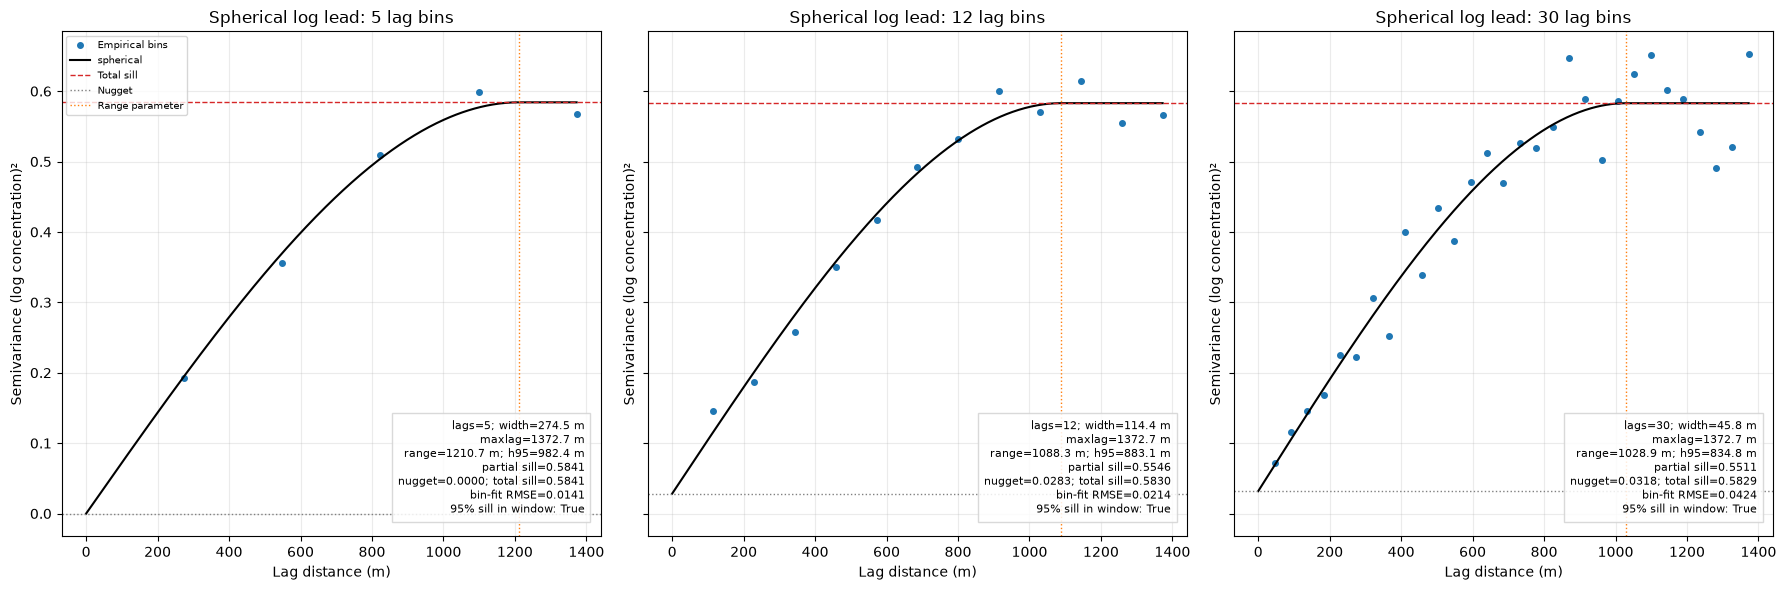

,Lag_width_m,Min_pairs,Max_pairs,Empty_bins,Effective_range_m,Partial_sill,Nugget,Variogram_RMSE
n_lags,,,,,,,,
5,274.533204,591,1444,0,1210.736477,0.584146,1.236043e-21,0.014129
12,114.388835,68,643,0,1088.349917,0.554640,2.832516e-02,0.021380
30,45.755534,1,264,0,1028.855706,0.551085,3.182221e-02,0.042382


In [5]:
# TODO:
# 1. Výpočet priestorových rozostupov:
#    - max_lag: medián párových vzdialeností pomocou pdist(coordinates) a np.median()
#    - ann_dist: priemerná vzdialenosť susedov cez KDTree(coordinates).query(k=2)
#    - n_lags_calc: podiel max_lag / ann_dist (zaokrúhlite na celé číslo)
#
# 2. Modelovanie semivariogramu skg.Variogram:
#    - Vytvorte 3 modely pre n_lags = [5, 12, 30]
#    - model='spherical', maxlag='median', use_nugget=True
#    - Šírku lagu v metroch zistite ako: V.bins[1] - V.bins[0]
#
# 3. Vyhodnotenie:
#    - Vykreslite modely do 1 riadku a 3 stĺpcov (plt.subplots(1, 3, sharey=True))
#    - Vytvorte DataFrame s metrikami: šírka lagu, min/max počet párov (V.bin_count) a RMSE (V.rmse)

pair_distances = pdist(coordinates)
max_lag = float(np.median(pair_distances))
ann_dist = float(KDTree(coordinates).query(coordinates, k=2)[0][:, 1].mean())
n_lags_calc = int(np.rint(max_lag / ann_dist))
print(f'Median pair distance: {max_lag:.3f} m; ANN: {ann_dist:.3f} m; '
      f'ratio: {max_lag / ann_dist:.3f}; derived bins: {n_lags_calc}.')
lead_lag_models, lag_rows = {}, []
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, count in zip(axes, [5, 12, 30]):
    v = fit_variogram(log_lead, model='spherical', n_lags=count, maxlag='median', use_nugget=True)
    lead_lag_models[count] = v
    lag_rows.append(plot_variogram(v, ax, f'Spherical log lead: {count} lag bins'))
axes[0].legend(loc='upper left', fontsize=7)
fig.tight_layout()
plt.show()
lead_lag_comparison = pd.DataFrame(lag_rows).set_index('n_lags')
display(lead_lag_comparison[['Lag_width_m', 'Min_pairs', 'Max_pairs', 'Empty_bins',
                             'Effective_range_m', 'Partial_sill', 'Nugget', 'Variogram_RMSE']])
lead_lag_comparison.to_csv(results_dir / 'lead_lag_comparison.csv')


### Exercise 3 — interpretation

The mean nearest-neighbor distance is computed from the second KDTree result, because the first result is the point itself. Dividing the median pair distance by ANN derives a representative number of bins rather than selecting it from forecast errors. The explicitly requested 5/12/30-bin comparison is retained even if a different dataset would give a derived value other than 12.

Five bins smooth away short-distance detail; 30 bins give finer detail but fewer pairs per class. Pair counts identify weakly supported or empty classes. `V.rmse` is the error of the theoretical curve against its own empirical bins, in squared-log-concentration units. Because bin definitions change across columns, a smaller bin-fit RMSE alone is not a fair predictive ranking.

**Reference results:** median distance = **1372.666 m**, ANN = **111.689 m**, giving **12** derived bins. The minimum pair count falls from **591** with 5 bins to **68** with 12 and only **1** with 30. Bin-fit RMSE values are 0.01413, 0.02138, and 0.04238 respectively; the fine 30-bin curve is visibly less stable.

### Typy semivariogramov, dosah(range), sill(prah), nugget(efekt)
Zvolený model ovplyvňuje predikciu neznámych hodnôt, obzvlášť vtedy, keď sa výrazne líši tvar krivky v blízkosti počiatku (pri malých vzdialenostiach).

Čím strmšia je krivka v blízkosti počiatku, tým väčší vplyv budú mať na predikciu najbližší susedia. V dôsledku toho bude výsledný interpolovaný povrch menej hladký (členitejší).

- **sférický**: Vykazuje postupný pokles priestorovej autokorelácie (ekvivalentné nárastu semivariancie) až po určitú vzdialenosť, za ktorou je už autokorelácia nulová.

- **exponenciálny**: Keď priestorová autokorelácia klesá exponenciálne s rastúcou vzdialenosťou. V tomto prípade autokorelácia úplne zaniká až v nekonečnej vzdialenosti.

Voľba toho, ktorý model použiť, vychádza z priestorovej autokorelácie v dátach a z predchádzajúcich odborných znalostí o skúmanom jave.

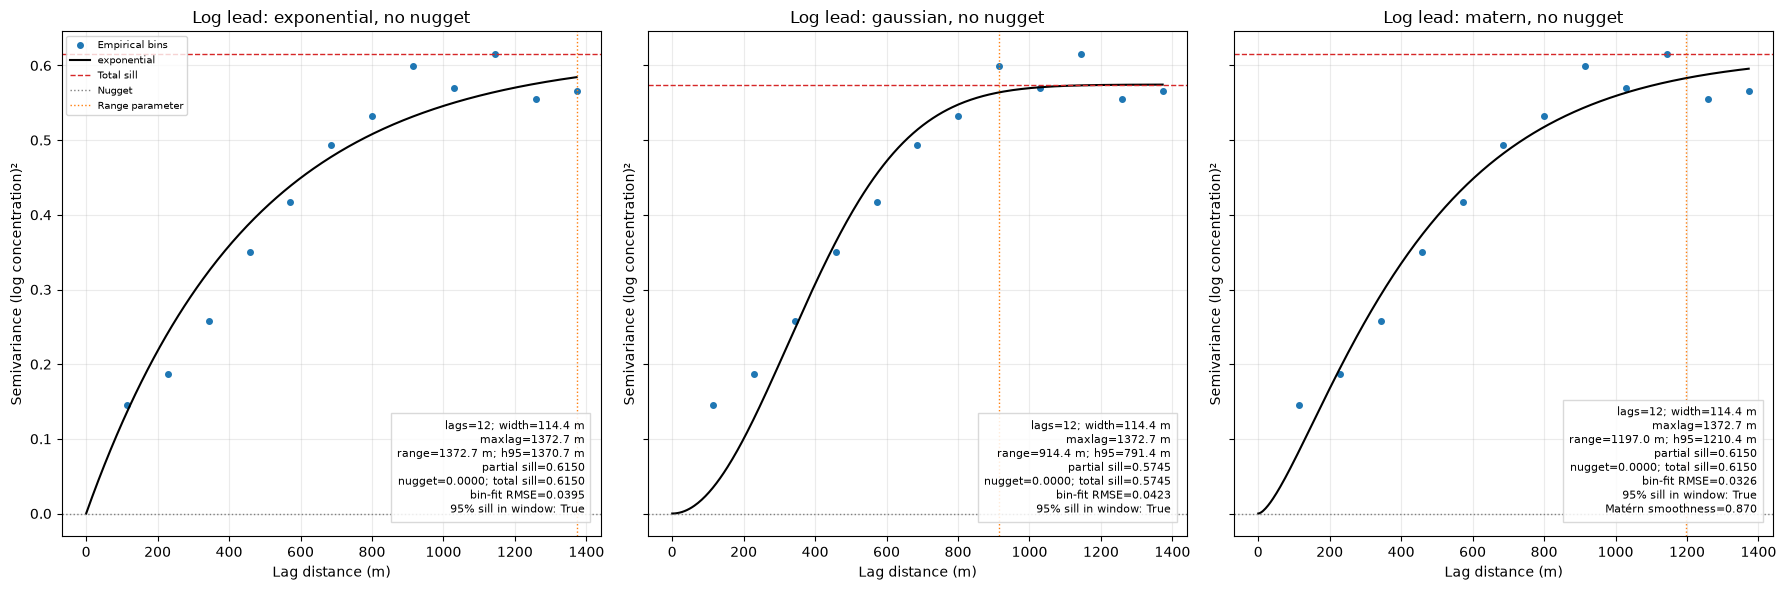

,Effective_range_m,Partial_sill,Total_sill,Smoothness,Variogram_RMSE,Practical_sill_95pct_in_window
Model,,,,,,
exponential,1372.666019,0.614996,0.614996,NaN,0.039537,True
gaussian,914.436561,0.574478,0.574478,NaN,0.042342,True
matern,1196.958677,0.614996,0.614996,0.870113,0.032574,True


In [6]:
# TODO:
# 1. S log_lead otestujte a na grafe porovnajte 3 teoretické modely: exponential, gaussian, matern.
#    - maxlag='median', n_lags=12, use_nugget=False.
# 2. Z V.describe() a V.rmse vypíšte kľúčové parametre: dosah(effective_range), prah(sill) a RMSE.

lead_family_models, family_rows = {}, []
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, model in zip(axes, ['exponential', 'gaussian', 'matern']):
    v = fit_variogram(log_lead, model=model, n_lags=12, maxlag='median', use_nugget=False)
    lead_family_models[model] = v
    family_rows.append(plot_variogram(v, ax, f'Log lead: {model}, no nugget'))
axes[0].legend(loc='upper left', fontsize=7)
fig.tight_layout()
plt.show()
lead_family_comparison = pd.DataFrame(family_rows).set_index('Model')
display(lead_family_comparison[['Effective_range_m', 'Partial_sill', 'Total_sill',
                                'Smoothness', 'Variogram_RMSE', 'Practical_sill_95pct_in_window']])
lead_family_comparison.to_csv(results_dir / 'lead_family_comparison.csv')


### Exercise 4 — interpretation

All three families use the same observations, 12 bins, median cutoff, and zero nugget, making the comparison more controlled than a comparison across different binnings. Exponential rises more sharply near zero, Gaussian is smoother there, and Matérn has an additional smoothness parameter. Its extra flexibility must be considered when interpreting an improved fit.

In this library, `describe()['sill']` is the **partial sill**, with total plateau equal to partial sill plus nugget. Exponential/Gaussian/Matérn approach that plateau asymptotically. The helper therefore calculates an actual 95%-of-structured-sill distance `h95` from the fitted function. It does not assume all families' reported range parameters use exactly the same 95% convention.

**Reference results:** among these no-nugget fits, Matérn has the lowest bin-fit RMSE (**0.03257**), versus exponential **0.03954** and Gaussian **0.04234**. Its smoothness is approximately **0.8701**. Exponential's fitted range reaches the **1372.666 m** upper fitting limit, so its range should not be treated as independently well identified.

------
**Dosah**: Vzdialenosť, za ktorou zostáva reziduálna závislosť zanedbateľná.

**Prah**: Hodnota semivariancie, pri ktorej model semivariogramu dosiahne dosah.

**Efekt**:  skok pri počiatku spôsobený chybou merania alebo variabilitou pod mierkou
vzorkovania

Cieľom je nájsť takú matematickú krivku, ktorá cez empirické body prechádza s čo najmenšou chybou.



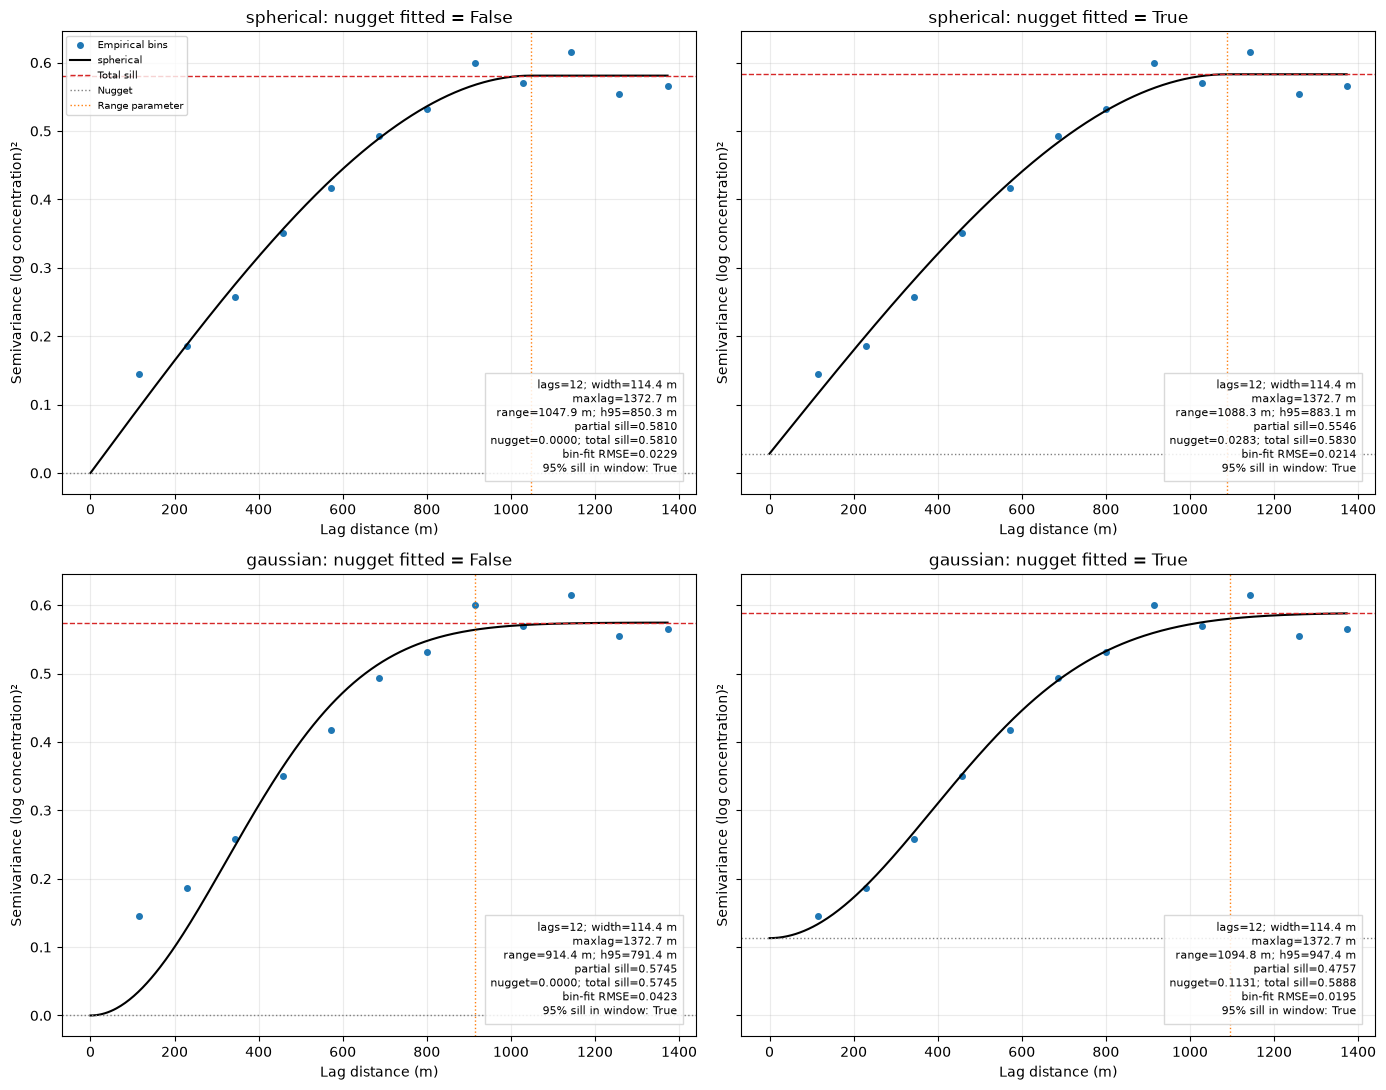

Effective_range_m  Partial_sill    Nugget  Total_sill  \
Model     Use_nugget                                                          
spherical False             1047.928033      0.580978  0.000000    0.580978   
          True              1088.349917      0.554640  0.028325    0.582965   
gaussian  False              914.436561      0.574478  0.000000    0.574478   
          True              1094.765412      0.475742  0.113086    0.588828   

                      Variogram_RMSE  
Model     Use_nugget                  
spherical False             0.022897  
          True              0.021380  
gaussian  False             0.042342  
          True              0.019540

In [7]:
# TODO:
# 1. Pre modely spherical a gaussian nafitujte verziu bez nuggetu (use_nugget=False) aj s nuggetom (use_nugget=True) a porovnajte na grafe
# 2. Zostavte porovnávaciu tabuľku (DataFrame) s metrikami z V.describe() a V.rmse: dosah, prah, nugget a RMSE.

lead_nugget_models, nugget_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharey=True)
for row, model in enumerate(['spherical', 'gaussian']):
    for column, use_nugget in enumerate([False, True]):
        v = fit_variogram(log_lead, model=model, n_lags=12, maxlag='median', use_nugget=use_nugget)
        lead_nugget_models[(model, use_nugget)] = v
        metrics = plot_variogram(v, axes[row, column], f'{model}: nugget fitted = {use_nugget}')
        metrics['Use_nugget'] = use_nugget
        nugget_rows.append(metrics)
axes[0, 0].legend(loc='upper left', fontsize=7)
fig.tight_layout()
plt.show()
lead_nugget_comparison = pd.DataFrame(nugget_rows).set_index(['Model', 'Use_nugget'])
display(lead_nugget_comparison[['Effective_range_m', 'Partial_sill', 'Nugget', 'Total_sill', 'Variogram_RMSE']])
lead_nugget_comparison.to_csv(results_dir / 'lead_nugget_comparison.csv')


### Exercise 5 — interpretation

The nugget represents a discontinuity immediately away from zero separation, which can arise from measurement error or variation below the sampling resolution. A fitted positive intercept should not be interpreted as the semivariance of a location with itself: the latter is zero. Pairwise kriging matrices retain a zero diagonal.

Adding a nugget introduces a parameter, so an improved in-sample curve fit alone does not establish a better forecasting model. The total sill is reported separately from the partial sill to keep the comparison consistent across nugget settings. For this lead comparison, default fitting bounds can constrain the range to the fitted distance window; a range at that boundary warrants caution about identifying a plateau.

**Reference results:** spherical nugget rises from zero to **0.02833**, and bin-fit RMSE falls from **0.02290** to **0.02138**. For Gaussian the fitted nugget is **0.11309**, reducing bin-fit RMSE from **0.04234** to **0.01954**. The Gaussian curve benefits more from fitting the short-distance discontinuity in this comparison.

### Smerové semivariogramy

Anizotropia znamená, že priestorová závislosť sa mení nielen so vzdialenosťou, ale aj so smerom.

Kým izotropný model predpokladá rovnaké správanie vo všetkých smeroch (tvar kruhu), anizotropný model dosahuje prah v niektorých smeroch rýchlejšie než v iných (tvar elipsy). Opisuje sa tromi parametrami:

hlavný dosah (major range): dĺžka v smere najsilnejšej/najdlhšej závislosti,
vedľajší dosah (minor range): dĺžka v kolmom smere s kratšou závislosťou,
uhol rotácie: natočenie hlavného smeru v priestore (azimuth).


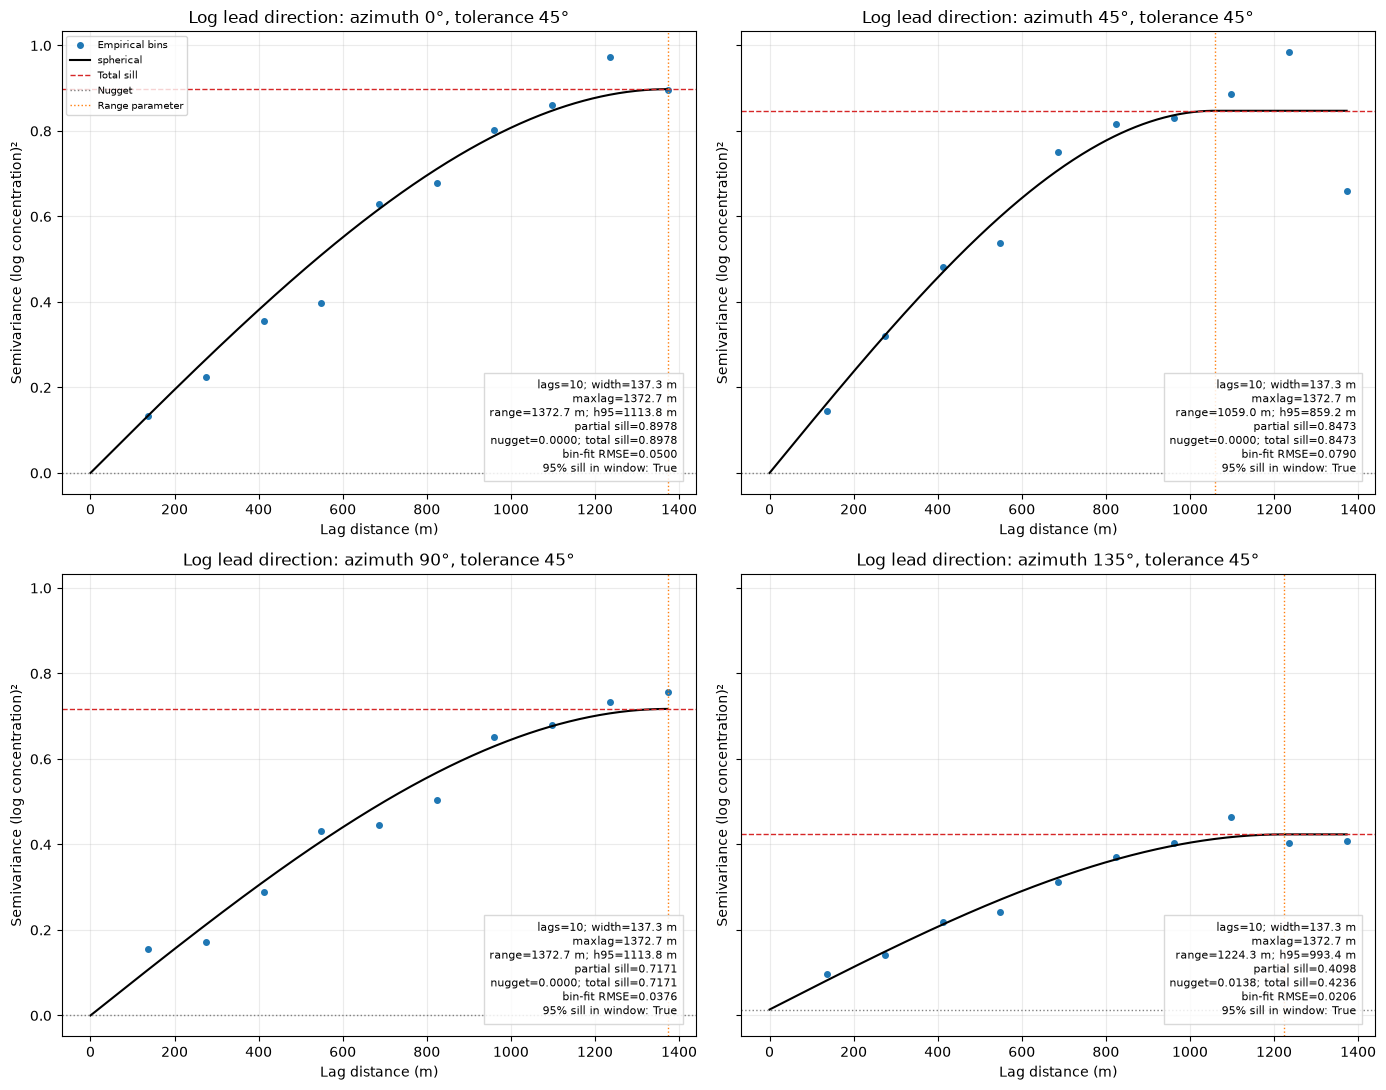

,Effective_range_m,Partial_sill,Nugget,Variogram_RMSE,Min_pairs,Empty_bins,Range_at_window_limit
Azimuth_deg,,,,,,,
0,1372.666019,0.897845,9.801277e-10,0.050005,33,0,True
45,1058.964206,0.847268,2.683893e-12,0.079047,20,0,False
90,1372.666019,0.717129,4.935049e-08,0.037559,28,0,True
135,1224.308143,0.409818,1.381583e-02,0.020608,25,0,False


In [8]:
# TODO:
# 1. Zadefinujte 4 hlavné smery: azimuths = [0, 45, 90, 135].
# 2. Vytvorte Variogram pre každý smer s parametrami:
#    - azimuth=az, tolerance=45, model='spherical', n_lags=10, maxlag='median', use_nugget=True.
# 3. Vykreslite variogram pre každý azimut a porovnajte ich dosah(effective_range).

azimuths = [0, 45, 90, 135]
directional_models, direction_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharey=True)
for ax, az in zip(axes.ravel(), azimuths):
    # A plain Variogram ignores directional selection; use DirectionalVariogram.
    v = skg.DirectionalVariogram(coordinates, log_lead, azimuth=az, tolerance=45,
                                 model='spherical', n_lags=10, maxlag='median', use_nugget=True,
                                 estimator='matheron', bin_func='even', normalize=False,
                                 directional_model='triangle', bandwidth='q33')
    directional_models[az] = v
    metrics = plot_variogram(v, ax, f'Log lead direction: azimuth {az}°, tolerance 45°')
    metrics['Azimuth_deg'] = az
    metrics['Range_at_window_limit'] = np.isclose(metrics['Effective_range_m'], metrics['Maxlag_m'], rtol=1e-4)
    direction_rows.append(metrics)
axes[0, 0].legend(loc='upper left', fontsize=7)
fig.tight_layout()
plt.show()
direction_comparison = pd.DataFrame(direction_rows).set_index('Azimuth_deg')
display(direction_comparison[['Effective_range_m', 'Partial_sill', 'Nugget', 'Variogram_RMSE',
                               'Min_pairs', 'Empty_bins', 'Range_at_window_limit']])
direction_comparison.to_csv(results_dir / 'lead_directional_comparison.csv')


### Exercise 6 — interpretation

The directional task requires `DirectionalVariogram`, not an ordinary isotropic `Variogram` with unused azimuth keywords. SciKit-GStat defines 0° as east and positive azimuth clockwise. For undirected pair axes, 0° is E–W, 45° NW–SE, 90° N–S, and 135° NE–SW. The 45° tolerance and the explicitly retained default-style triangular search band (`q33`) restrict which pairs enter each fit.

Compare ranges together with the counts and empirical shapes, since directional subsets have different support. A fitted range at its maximum allowed distance is not a well-identified major axis. These four exploratory fits can suggest anisotropy; they do not by themselves provide a robust anisotropic covariance model or remove a broad spatial trend. The subsequent Ordinary Kriging is the requested isotropic baseline, so its uncertainty does not include directional-model uncertainty.

**Reference results:** 45° and 135° fits give ranges of approximately **1058.96 m** and **1224.31 m**. The 0° and 90° ranges both reach the **1372.67 m** fitting boundary. The different shapes, sills, and pair support suggest directional differences, but those two boundary fits prevent a reliable major/minor range ratio from this exercise alone.

------
### 2. Predikcia

Kriging vytvára váhy z okolitých nameraných hodnôt na odhad v nenameraných lokalitách. Namerané hodnoty majú najbližšie k odhadovanému miestu najväčší vplyv. Váhy krigingu vychádzajú zo semivariogramu, ktorý bol odvodený z priestorovej povahy dát. Na vytvorenie spojitého povrchu sa predikcie počítajú pre každú lokalitu (stred bunky) v záujmovom území na základe semivariogramu a priestorového usporiadania okolitých nameraných hodnôt.

* Ordinary Kriging: Predpokladá, že stredná hodnota (priemer) je v celom území konštantná, hoci jej presnú hodnotu nepoznáme. Je to rozumný predpoklad, pokiaľ neexistuje konkrétny vedecký dôvod ho odmietnuť.

* Universal Kriging: Predpokladá, že v dátach existuje trend – napríklad vplyv prevládajúceho vetra alebo spád terénu, ktorý sa dá opísať deterministickou matematickou funkciou (polynómom). Tento polynóm sa od pôvodných nameraných hodnôt odpočíta a priestorová autokorelácia (semivariogram) sa modeluje až zo zvyškových náhodných chýb (rezíduí)

Lead kriging model:
Model                                   spherical
n_lags                                         12
Maxlag_m                              1372.666019
Lag_width_m                            114.388835
Min_pairs                                      68
Max_pairs                                     643
Empty_bins                                      0
Effective_range_m                     1088.349917
Partial_sill                              0.55464
Nugget                                   0.028325
Total_sill                               0.582965
Variogram_RMSE                            0.02138
h95_m                                  883.088594
Structured_sill_fraction_at_maxlag            1.0
Practical_sill_95pct_in_window               True
Exact_plateau_in_window                      True
Smoothness                                    NaN
lead: 75×75=5625 grid cells; inside hull=2816; predicted=2816; unsupported inside=0.
Back-transformed median: 38.683 to 590.971 pp

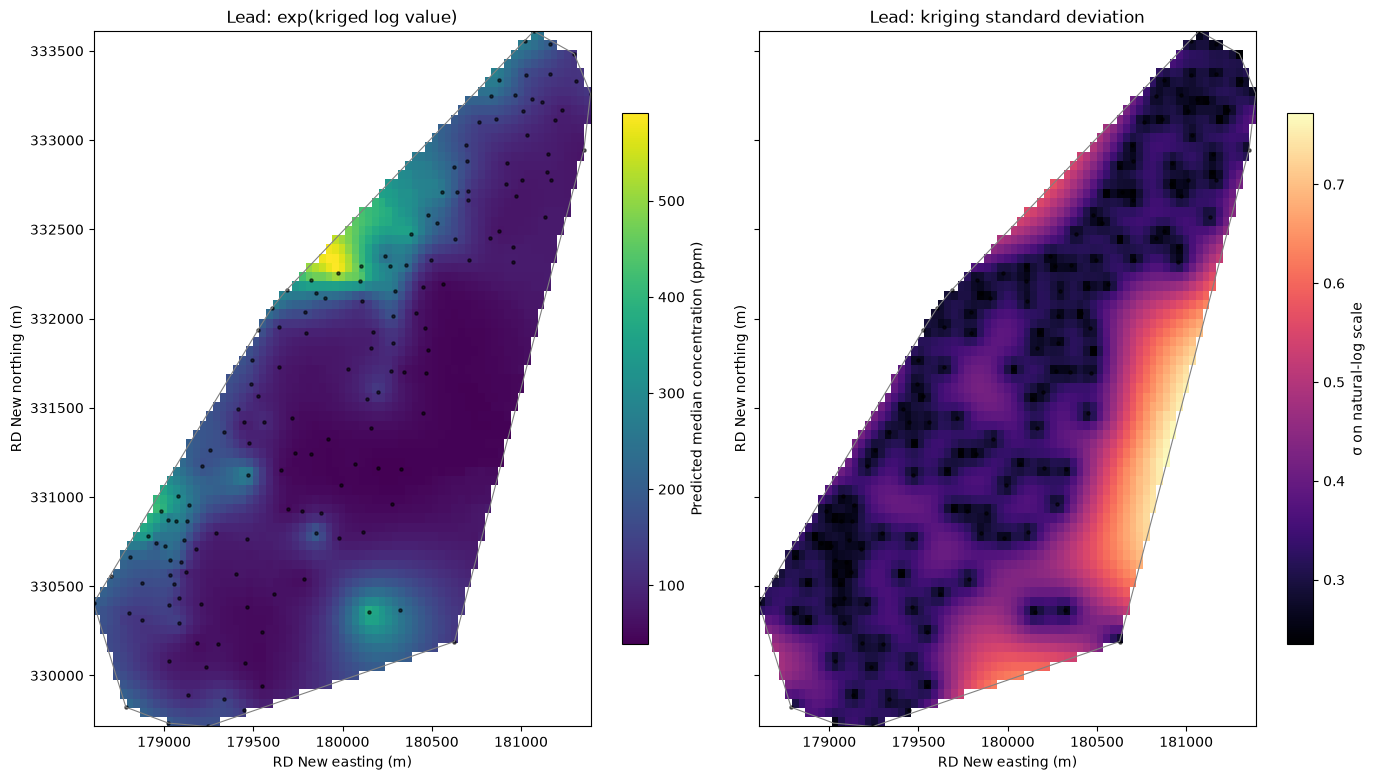

In [9]:
# TODO:
# 1. Zvoľte sférický semivariogram (n_lags=12, maxlag='median', use_nugget=True).
# 2. Inicializujte skg.OrdinaryKriging().
#    - min_points / max_points: lokálne okolie 5 až 20 najbližších susedov.
# 3. Na mriežke 75x75 predikujte hodnoty aj neistotu (sigma) a orežte ich konvexným obalom (Delaunay).
# 4. Preveďte predikciu na pôvodnú škálu cez np.exp().
# 5. Vykreslite reálnu predikciu v ppm a krigingovú neistotu.

lead_kriging_variogram = fit_variogram(log_lead, model='spherical', n_lags=12,
                                      maxlag='median', use_nugget=True)
print('Lead kriging model:')
print(pd.Series(variogram_metrics(lead_kriging_variogram)).to_string())
lead_surface = kriging_surface(lead_kriging_variogram, 'lead', size=75)


### Exercise 7 — interpretation

The 75×75 grid uses cell centers in RD New meters. Delaunay membership masks cells outside the convex hull. This is a geometric interpolation mask, not a riverbank, soil, or land-use boundary; it does not guarantee dense support everywhere inside. Each estimate uses 5–20 nearest points **within the fitted range**. Unsupported cells remain NaN and are counted rather than filled by extrapolation.

The library's `ok.sigma` contains kriging **variance**. The uncertainty map displays its square root, sigma, on the natural-log scale. It reflects the fitted model and sample geometry, conditional on the estimated variogram; it omits uncertainty from choosing/fitting the variogram, possible trend, and possible anisotropy.

`exp(predicted_log)` is the requested back transformation to ppm. Under a Gaussian log-scale predictive approximation it estimates the conditional **median**, not an unbiased arithmetic mean. Exported columns also provide explicitly labeled lognormal mean/SD approximations and pointwise intervals `exp(mu ± 1.96 sigma)`. Their validity depends on the Gaussian and covariance assumptions. The GeoTIFF has bands for median ppm, log-scale SD, and log-scale variance.

Kriging weights are solved jointly from the variogram and sampling configuration. Distance alone does not determine their ranking, and weights need not all be positive.

**Reference results:** the requested lead model has range **1088.35 m**, partial sill **0.55464**, nugget **0.02833**, and total sill **0.58297**. All **2816** grid cells inside the hull are supported. Back-transformed median predictions span **38.68–590.97 ppm**, with log-scale standard deviations **0.235–0.772**.

---
## Bonus 2B
Pre koncentráciu kadmia otestujte 6 kombinácií semivariogramov vzniknutých kombináciou troch hodnôt maxlag (median, mean, 0.5), s odvodeným počtom lagov a dvoch teoretických modelov (spherical, gaussian). Modely vizualizujte so všetkými parametrami a overte, či dosiahli prah. Zvoľte vhodný model s ktorým vykonáte Ordinary Kriging s výslednou mapou predikcie v ppm a mapou neistoty $\sigma$.

   - median — medián párových vzdialeností s np.median()
   - mean — priemer párových vzdialeností s np.mean()
   - 0.5 — polovica maximálnej vzdialenosti s np.max()*0.5



### Bonus — six cadmium variograms and a transparent sill check

Follow the lead workflow on **log_cadmium**. Use three cutoff rules: `np.median(pdist(xy))`, `np.mean(pdist(xy))`, and `0.5*np.max(pdist(xy))`. For each, derive the bin count as `round(maxlag/ANN)` (with at least three bins for a three-parameter nugget model). Combine these settings with spherical and Gaussian families to obtain exactly six fits. Every candidate uses Matheron, equal-width bins, and a fitted nugget.

Use the same nonnegative parameter-bound rule for all six candidates: range at most `3*maxlag`, and partial sill/nugget each at most three times the sample log variance. Allowing range beyond maxlag avoids forcing a plateau into the fitted window. The parameter-bound check is reported.

For spherical, an **exact plateau** is reached at its range; Gaussian reaches its exact plateau only asymptotically. The practical check tests whether the curve has reached **95% of its structured rise above the nugget** by the last fitted lag. Report the fitted curve's actual fraction, `h95`, and the exact-plateau indicator separately. This checks the fitted model, not independent evidence that the empirical process has a stationary sill.

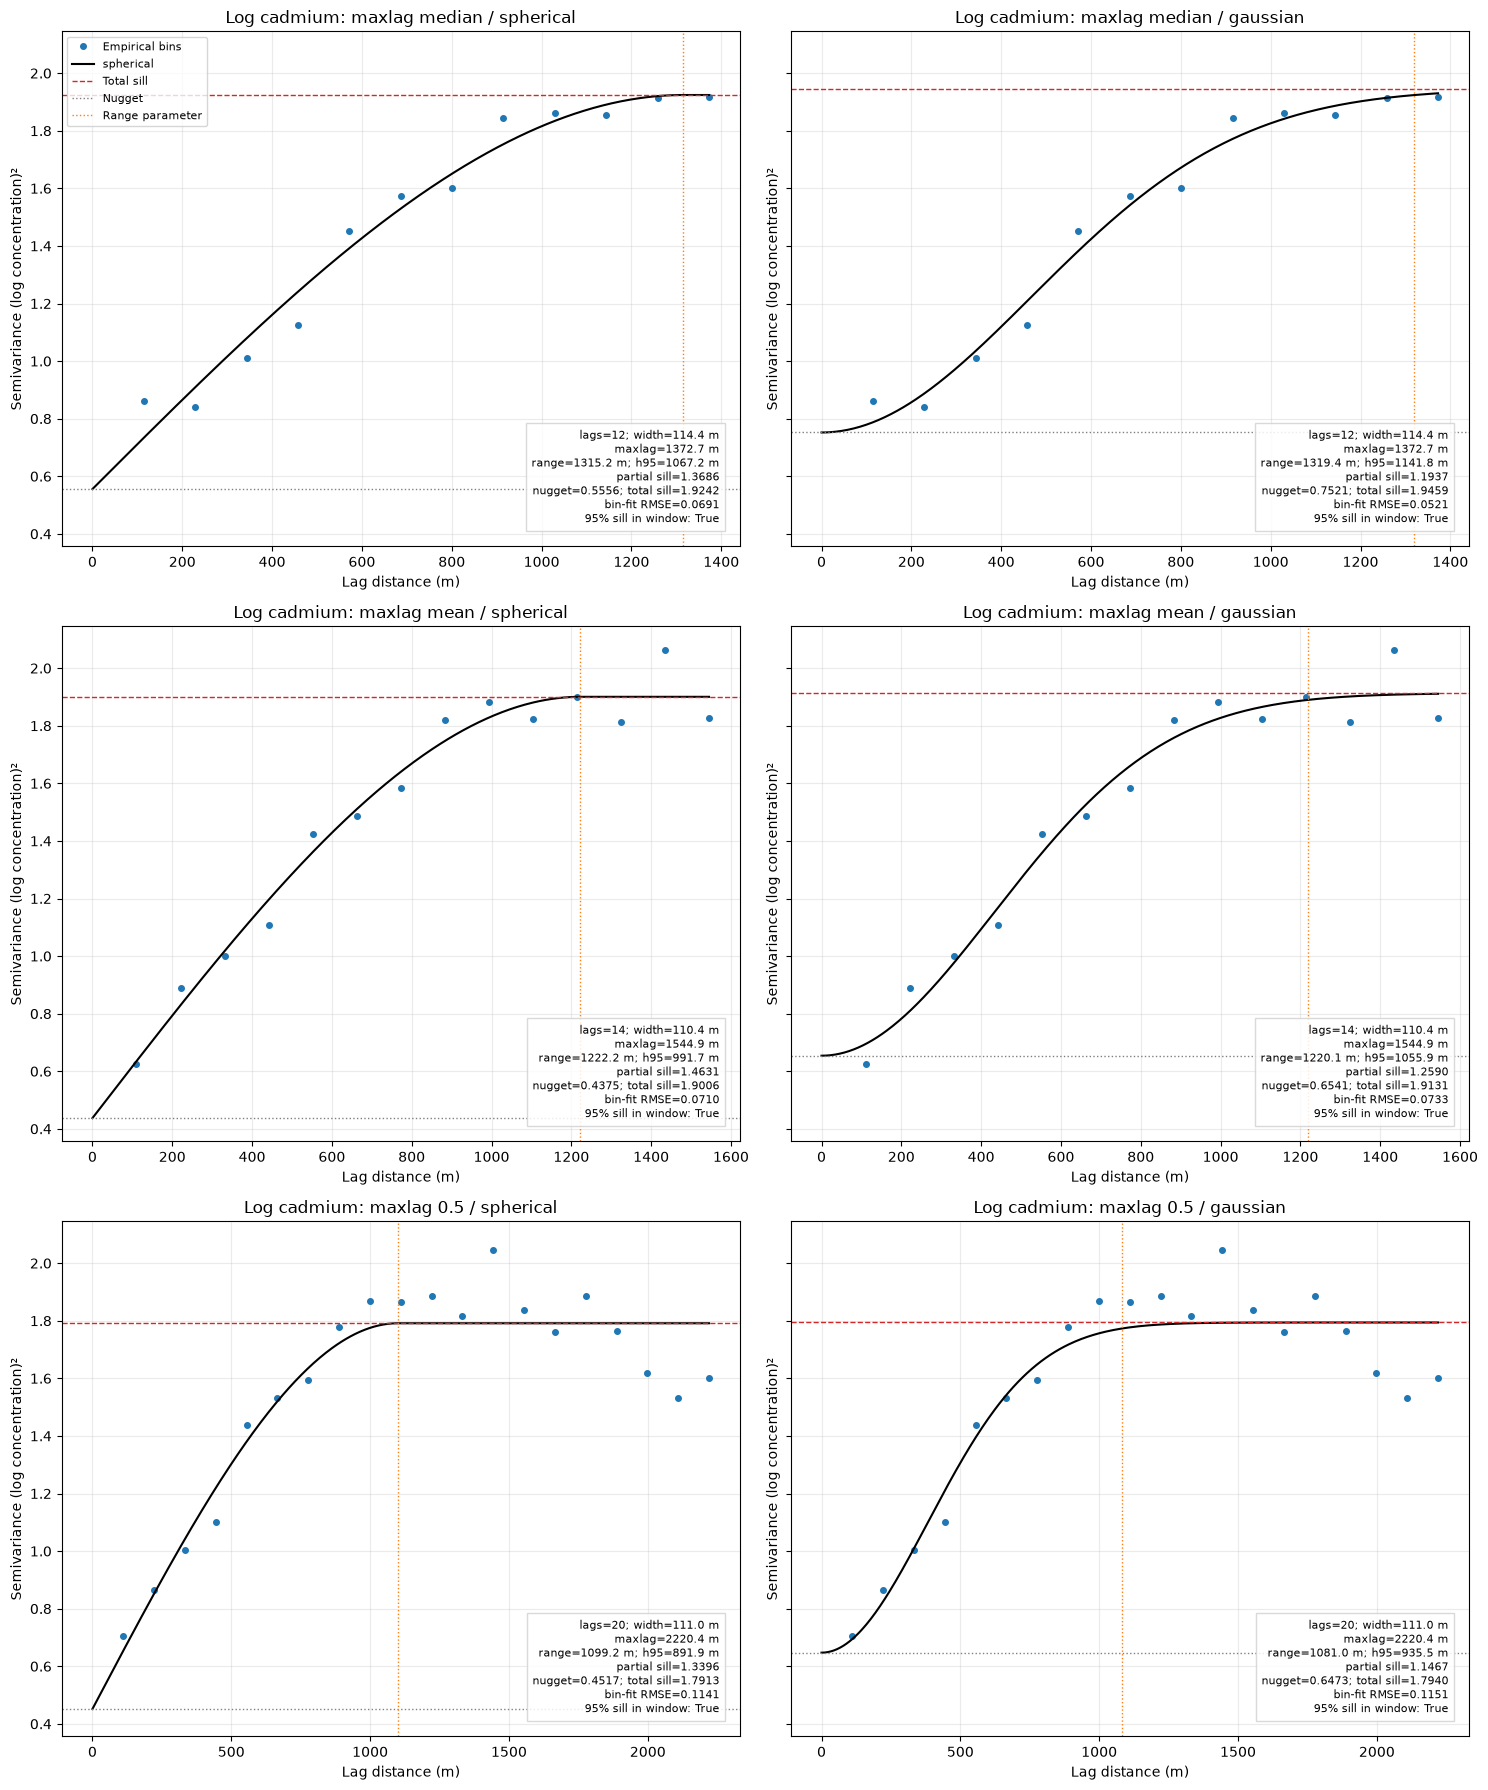

,Maxlag_rule,Model,ANN_m,n_lags,Lag_width_m,Maxlag_m,Effective_range_m,Partial_sill,Nugget,Total_sill,Variogram_RMSE,h95_m,Structured_sill_fraction_at_maxlag,Practical_sill_95pct_in_window,Exact_plateau_in_window,Min_pairs,Empty_bins,Range_at_upper_bound
Candidate,,,,,,,,,,,,,,,,,,
median/spherical,median,spherical,111.689493,12,114.388835,1372.666019,1315.213803,1.368595,0.555631,1.924226,0.069104,1067.166258,1.000000,True,True,68,0,False
median/gaussian,median,gaussian,111.689493,12,114.388835,1372.666019,1319.374855,1.193748,0.752132,1.945880,0.052110,1141.799126,0.986828,True,False,68,0,False
mean/spherical,mean,spherical,111.689493,14,110.353402,1544.947635,1222.210479,1.463097,0.437457,1.900554,0.070968,991.703235,1.000000,True,True,61,0,False
mean/gaussian,mean,gaussian,111.689493,14,110.353402,1544.947635,1220.126603,1.259044,0.654098,1.913142,0.073269,1055.908777,0.998360,True,False,61,0,False
0.5/spherical,0.5,spherical,111.689493,20,111.019109,2220.382174,1099.227848,1.339589,0.451745,1.791333,0.114067,891.914962,1.000000,True,True,64,0,False
0.5/gaussian,0.5,gaussian,111.689493,20,111.019109,2220.382174,1081.046010,1.146731,0.647269,1.794001,0.115114,935.547154,1.000000,True,False,64,0,False


Derived cutoff / bin counts:
                     Maxlag_m  n_lags
Candidate                            
median/spherical  1372.666019      12
median/gaussian   1372.666019      12
mean/spherical    1544.947635      14
mean/gaussian     1544.947635      14
0.5/spherical     2220.382174      20
0.5/gaussian      2220.382174      20


In [10]:
log_cadmium = meuse.log_cadmium.to_numpy()
maxlag_rules, cadmium_families = ['median', 'mean', '0.5'], ['spherical', 'gaussian']
cadmium_models, cadmium_rows = {}, []
fig, axes = plt.subplots(3, 2, figsize=(15, 18), sharey=True)
for row, rule in enumerate(maxlag_rules):
    for column, family in enumerate(cadmium_families):
        candidate = f'{rule}/{family}'
        v, settings = fit_cadmium(coordinates, log_cadmium, rule, family)
        cadmium_models[candidate] = v
        metrics = plot_variogram(v, axes[row, column], f'Log cadmium: maxlag {rule} / {family}')
        metrics.update(settings)
        metrics['Candidate'] = candidate
        metrics['Range_at_upper_bound'] = np.isclose(metrics['Effective_range_m'], 3 * metrics['Maxlag_m'], rtol=1e-4)
        cadmium_rows.append(metrics)
axes[0, 0].legend(loc='upper left', fontsize=8)
fig.tight_layout()
fig.savefig(results_dir / 'cadmium_six_variograms.png', dpi=160, bbox_inches='tight')
plt.show()
cadmium_comparison = pd.DataFrame(cadmium_rows).set_index('Candidate')
display(cadmium_comparison[['Maxlag_rule', 'Model', 'ANN_m', 'n_lags', 'Lag_width_m', 'Maxlag_m',
                             'Effective_range_m', 'Partial_sill', 'Nugget', 'Total_sill', 'Variogram_RMSE',
                             'h95_m', 'Structured_sill_fraction_at_maxlag',
                             'Practical_sill_95pct_in_window', 'Exact_plateau_in_window',
                             'Min_pairs', 'Empty_bins', 'Range_at_upper_bound']])
cadmium_comparison.to_csv(results_dir / 'cadmium_six_variograms.csv')
print('Derived cutoff / bin counts:')
print(cadmium_comparison[['Maxlag_m', 'n_lags']].to_string())

### Bonus — predictive comparison before selecting the final model

Bin-fit RMSE is not directly comparable across different cutoff/bin definitions. To support model choice, apply the same seeded **five-fold held-out-point validation** to all six candidates. At each fold, refit the variogram using training concentrations only, and recompute the cutoff, ANN, bin count, and bounds from training data. Held-out concentrations are used only after prediction for scoring.

These interspersed folds assess interpolation among nearby sampled locations, not extrapolation into a distant unobserved block. Scores used to select the model are internal validation scores; they are not an independent final test of the selected model. Report coverage and compare errors on the same common supported observations. Prefer a model reaching the practical sill, away from the range bound, with complete validation coverage; among those, choose the smallest common-point log RMSE. If none qualifies, stop for review rather than silently changing the rule.

Validated median/spherical: five folds completed.
Validated median/gaussian: five folds completed.
Validated mean/spherical: five folds completed.
Validated mean/gaussian: five folds completed.
Validated 0.5/spherical: five folds completed.
Validated 0.5/gaussian: five folds completed.
Shared supported validation points: 155 / 155
                  Variogram_RMSE  CV_log_MAE  CV_log_RMSE  CV_ppm_MAE  CV_ppm_RMSE  Coverage  Eligible_for_selection
Candidate                                                                                                           
mean/gaussian           0.073269    0.695673     0.959336    1.737012     3.046561  1.000000                    True
median/gaussian         0.052110    0.696941     0.960461    1.740693     3.048387  1.000000                    True
0.5/gaussian            0.115114    0.697610     0.962253    1.730556     3.025817  1.000000                    True
median/spherical        0.069104    0.703709     0.972238    1.744519     3.073306

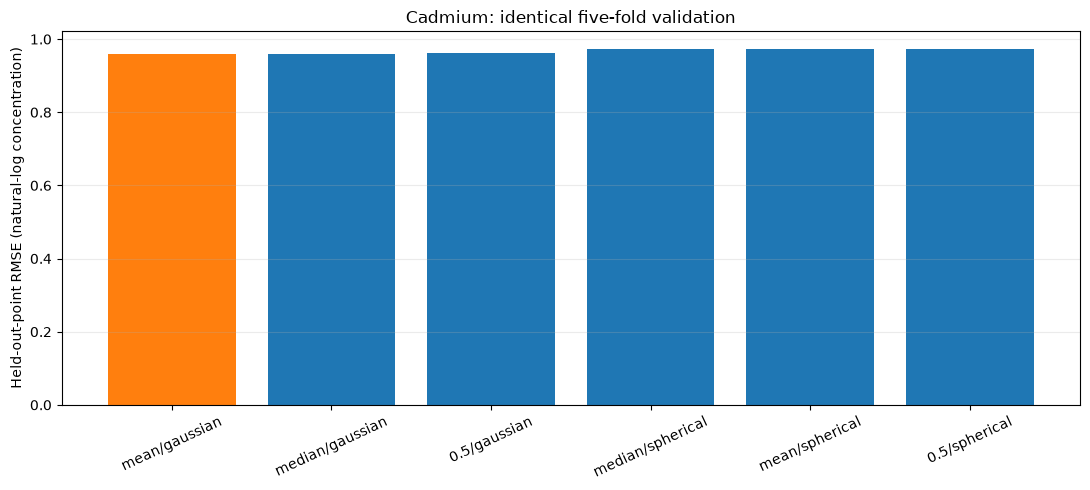

In [11]:
cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=42).split(coordinates))
cadmium_cv_rows, cadmium_cv_audit_rows = [], []
for candidate in cadmium_models:
    rule, family = candidate.split('/')
    for fold, (train_idx, test_idx) in enumerate(cv_folds, start=1):
        v, settings = fit_cadmium(coordinates[train_idx], log_cadmium[train_idx], rule, family)
        predicted, variance, _ = krige_points(v, coordinates[test_idx])
        cadmium_cv_audit_rows.append({'Candidate': candidate, 'Fold': fold,
                                      'Training_n': len(train_idx), 'Testing_n': len(test_idx),
                                      'Training_maxlag_m': v.bins[-1],
                                      'Training_ANN_m': settings['ANN_m'],
                                      'Training_n_lags': v.n_lags,
                                      'Training_range_m': v.describe()['effective_range'],
                                      'Supported_test_n': int(np.isfinite(predicted).sum()),
                                      'Overlap': len(set(train_idx) & set(test_idx))})
        for sample_id, pred, var in zip(test_idx, predicted, variance):
            cadmium_cv_rows.append({'Candidate': candidate, 'Fold': fold, 'Sample_id': sample_id,
                                    'Actual_log': log_cadmium[sample_id], 'Predicted_log': pred,
                                    'Variance_log2': var, 'Actual_ppm': meuse.cadmium.iloc[sample_id],
                                    'Predicted_median_ppm': np.exp(pred)})
    print(f'Validated {candidate}: five folds completed.')

cadmium_cv_predictions = pd.DataFrame(cadmium_cv_rows)
cadmium_cv_audit = pd.DataFrame(cadmium_cv_audit_rows)
cv_pivot = cadmium_cv_predictions.pivot(index='Sample_id', columns='Candidate', values='Predicted_log')
common_sample_ids = cv_pivot.index[np.isfinite(cv_pivot.to_numpy()).all(axis=1)]
if len(common_sample_ids) < 0.9 * len(meuse):
    raise ValueError('Too few jointly supported validation points for a reliable candidate comparison.')
cv_score_rows = []
for candidate, frame in cadmium_cv_predictions.groupby('Candidate', sort=False):
    common = frame.set_index('Sample_id').loc[common_sample_ids]
    log_error = common.Predicted_log - common.Actual_log
    ppm_error = common.Predicted_median_ppm - common.Actual_ppm
    cv_score_rows.append({'Candidate': candidate,
                          'Coverage': float(np.isfinite(frame.Predicted_log).mean()),
                          'Common_points': len(common), 'CV_log_MAE': log_error.abs().mean(),
                          'CV_log_RMSE': np.sqrt(log_error.pow(2).mean()),
                          'CV_ppm_MAE': ppm_error.abs().mean(), 'CV_ppm_RMSE': np.sqrt(ppm_error.pow(2).mean())})
cadmium_cv_scores = pd.DataFrame(cv_score_rows).set_index('Candidate')
cadmium_selection = cadmium_comparison.join(cadmium_cv_scores)
eligible = (cadmium_selection.Practical_sill_95pct_in_window
             & ~cadmium_selection.Range_at_upper_bound
             & cadmium_selection.Empty_bins.eq(0)
             & cadmium_selection.Coverage.eq(1.0))
cadmium_selection['Eligible_for_selection'] = eligible
if not eligible.any():
    raise ValueError('No candidate meets the declared sill, range, bin, and validation-coverage requirements.')
best_cadmium_name = cadmium_selection.loc[eligible, 'CV_log_RMSE'].idxmin()
best_cadmium_variogram = cadmium_models[best_cadmium_name]
print('Shared supported validation points:', len(common_sample_ids), '/', len(meuse))
print(cadmium_selection[['Variogram_RMSE', 'CV_log_MAE', 'CV_log_RMSE', 'CV_ppm_MAE', 'CV_ppm_RMSE',
                          'Coverage', 'Eligible_for_selection']].sort_values('CV_log_RMSE').to_string(
                              float_format=lambda value: f'{value:.6f}'))
print('Selected candidate:', best_cadmium_name)
cadmium_selection.to_csv(results_dir / 'cadmium_model_selection.csv')
cadmium_cv_predictions.to_csv(results_dir / 'cadmium_cv_predictions.csv', index=False)
cadmium_cv_audit.to_csv(results_dir / 'cadmium_cv_fit_audit.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ordered = cadmium_cv_scores.sort_values('CV_log_RMSE')
colors = ['tab:orange' if name == best_cadmium_name else 'tab:blue' for name in ordered.index]
ax.bar(ordered.index, ordered.CV_log_RMSE, color=colors)
ax.set(ylabel='Held-out-point RMSE (natural-log concentration)', title='Cadmium: identical five-fold validation')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

Final cadmium model, refitted using all available observations:
Candidate: mean/gaussian
Model                                    gaussian
n_lags                                         14
Maxlag_m                              1544.947635
Lag_width_m                            110.353402
Min_pairs                                      61
Max_pairs                                     621
Empty_bins                                      0
Effective_range_m                     1220.126603
Partial_sill                             1.259044
Nugget                                   0.654098
Total_sill                               1.913142
Variogram_RMSE                           0.073269
h95_m                                 1055.908777
Structured_sill_fraction_at_maxlag        0.99836
Practical_sill_95pct_in_window               True
Exact_plateau_in_window                     False
Smoothness                                    NaN
cadmium: 75×75=5625 grid cells; inside hull=2816; predicted=2

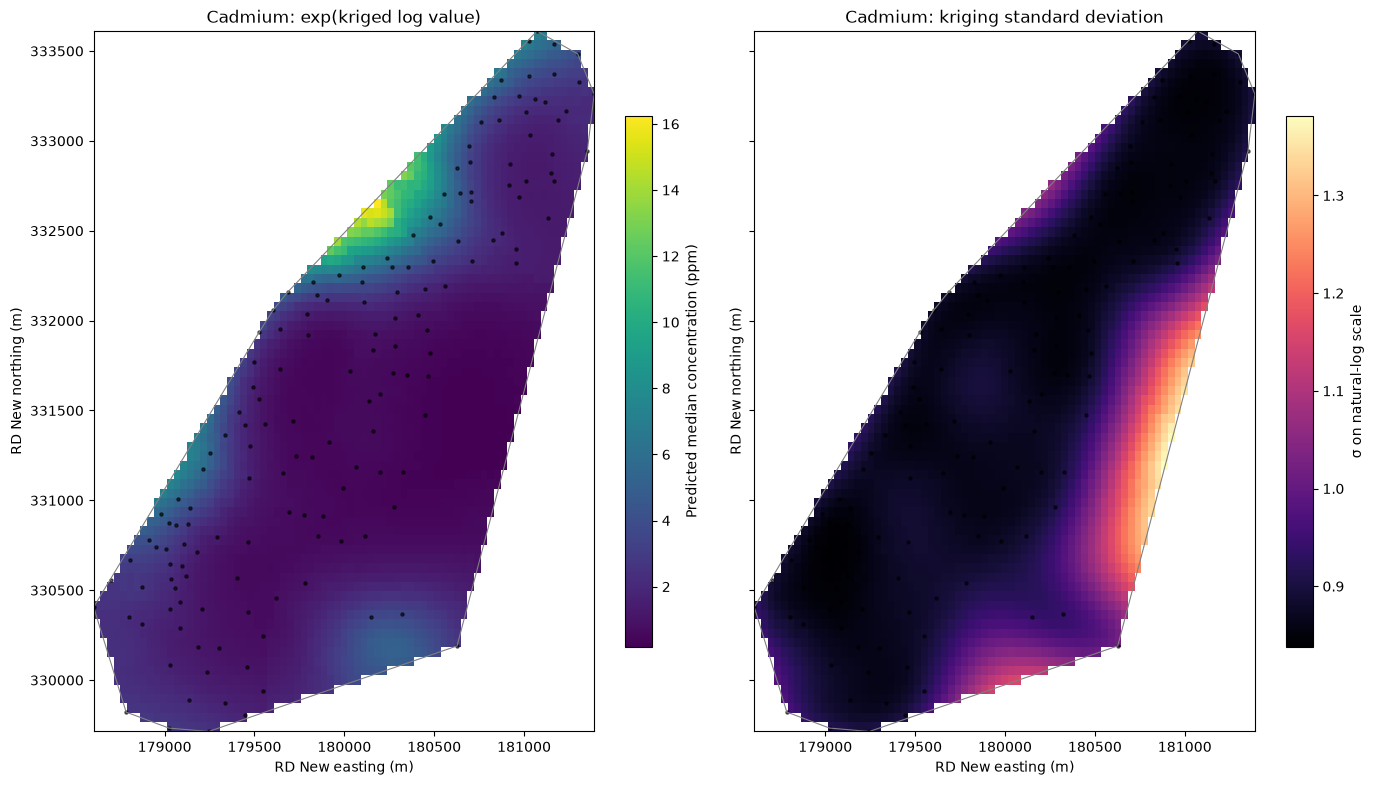

In [12]:
print('Final cadmium model, refitted using all available observations:')
print('Candidate:', best_cadmium_name)
print(pd.Series(variogram_metrics(best_cadmium_variogram)).to_string())
cadmium_surface = kriging_surface(best_cadmium_variogram, 'cadmium', size=75)

### Bonus — interpretation

The six-panel figure and exported comparison table show every candidate's cutoff, derived lag count, range, partial sill, nugget, total sill, bin-fit error, and practical-sill diagnostic. Spherical fits can reach the exact total sill within the distance window. Gaussian fits have no exact finite plateau; a practical 95% threshold is a transparent alternative. The reported fraction is measured above the nugget, so a large nugget cannot itself create a false positive for a reached structured sill.

The orange validation bar identifies the selected candidate under the declared rule. This choice uses predictive performance on the same held-out locations, rather than choosing whichever variogram happens to have the smallest error against a differently binned empirical curve. Its final full-data fit then generates the two required maps: back-transformed median concentration in ppm and kriging standard deviation on the log scale. Exported GeoTIFF/CSV results preserve the original CRS and uncertainty units.

White cells outside the hull are intentionally masked. Unsupported or singular predictions inside the hull, if present, also remain missing and are counted. High uncertainty can indicate sparse neighboring sampling, but it is not a direct measurement of high pollution or a guarantee of total prediction error. The isotropic Ordinary Kriging assumptions and the limited point-validation design should be kept in mind when using the surface beyond this exercise.

**Reference results for the supplied Meuse sample:**

| Maxlag rule | Cutoff (m) | Derived bins |
| --- | ---: | ---: |
| median | 1372.666 | 12 |
| mean | 1544.948 | 14 |
| half maximum | 2220.382 | 20 |

All six fitted curves reach the practical 95% structured sill within their windows; all three spherical models also reach an exact plateau. No candidate hits the deliberately wider range bound, and all six predict all **155** held-out observations in the common five-fold comparison.

The selected model is **mean / Gaussian**, with range parameter **1220.127 m**, partial sill **1.259044**, nugget **0.654098**, and total sill **1.913142**. Its true curve-based h95 is **1055.909 m**, and it reaches **99.84%** of the structured sill by maxlag. Gaussian does not reach the exact asymptotic plateau at a finite distance.

| Candidate | Bin-fit RMSE | CV log RMSE | CV ppm RMSE |
| --- | ---: | ---: | ---: |
| median / spherical | 0.069104 | 0.972238 | 3.073306 |
| median / Gaussian | 0.052110 | 0.960461 | 3.048387 |
| mean / spherical | 0.070968 | 0.972298 | 3.078571 |
| mean / Gaussian | 0.073269 | **0.959336** | 3.046561 |
| half maximum / spherical | 0.114067 | 0.972682 | 3.067527 |
| half maximum / Gaussian | 0.115114 | 0.962253 | **3.025817** |

Median/Gaussian has the smallest bin-fit error, but mean/Gaussian wins under the declared **log-scale predictive RMSE** criterion. Half-maximum/Gaussian has slightly lower ppm RMSE; a different prespecified objective would therefore select a different candidate. The differences among Gaussian candidates are small, and no statistical significance or universal superiority is claimed.

The final cadmium surface contains **2816 supported cells** inside the hull. Back-transformed median concentrations range from **0.181 to 16.244 ppm**, and log-scale standard deviations from **0.838 to 1.382**. The larger uncertainty along the sparsely sampled eastern edge is visible on the map. Both required maps are also saved as a standalone PNG, alongside a georeferenced GeoTIFF and the full grid CSV.

### References

- [SciKit-GStat variogram models](https://scikit-gstat.readthedocs.io/en/latest/reference/models.html), [directional variograms](https://scikit-gstat.readthedocs.io/en/latest/reference/directionalvariogram.html), and [Ordinary Kriging](https://scikit-gstat.readthedocs.io/en/latest/reference/kriging.html).
- [Kriging implementation: sigma stores variance](https://scikit-gstat.readthedocs.io/en/latest/_modules/skgstat/Kriging.html).
- [SciKit-GStat: methods and model conventions](https://doi.org/10.5194/gmd-15-2505-2022).
- Meuse measurements are distributed with R's **sp** package. Dataset attribution: Pebesma and Bivand (2005), *Classes and methods for spatial data in R*, and Bivand, Pebesma and Gómez-Rubio (2013), *Applied Spatial Data Analysis with R*, second edition. [SciKit-GStat data source and attribution](https://github.com/mmaelicke/scikit-gstat/tree/master/skgstat/data).